In [1]:
pip install opencv-python 'numpy<2' matplotlib

Defaulting to user installation because normal site-packages is not writeable
INFO: pip is looking at multiple versions of opencv-python to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 8.8 MB/s eta 0:00:0000:0100:01
  Attempting uninstall: opencv-python
    Found existing installation: opencv-python 4.13.0.92
    Uninstalling opencv-python-4.13.0.92:
      Successfully uninstalled opencv-python-4.13.0.92
Note: you may need to restart the kernel to use updated packages.


Text(0.5, 1.0, 'blurred with 9x9 filter')

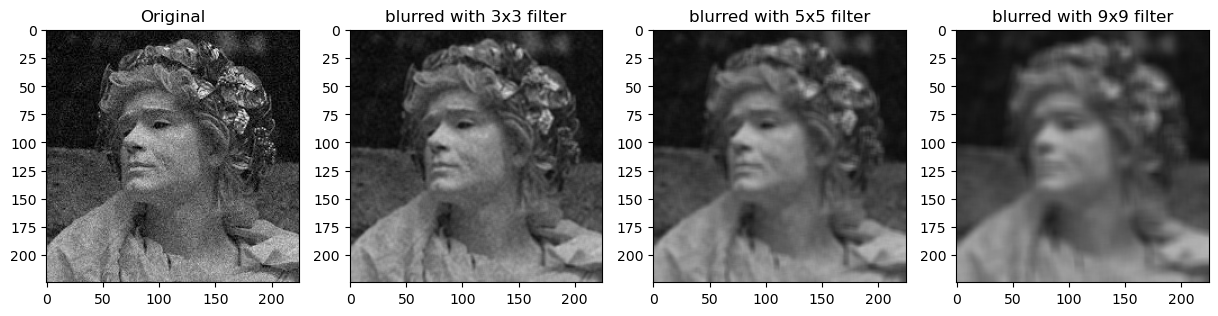

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('/Users/230363/Downloads/images.jpeg')

kernel_3x3 = np.ones((3, 3), np.float32) / 9

blurred = cv2.filter2D(image, -1, kernel_3x3)

kernel_5x5 = np.ones((5, 5), np.float32) / 25

blurred2 = cv2.filter2D(image, -1, kernel_5x5)

kernel_9x9 = np.ones((9, 9), np.float32) / 81

blurred3 = cv2.filter2D(image, -1, kernel_9x9)

plt.figure(figsize=[15,5])
plt.subplot(141);plt.imshow(image[...,::-1]);plt.title("Original")
plt.subplot(142);plt.imshow(blurred[...,::-1]);plt.title("blurred with 3x3 filter")
plt.subplot(143);plt.imshow(blurred2[...,::-1]);plt.title("blurred with 5x5 filter")
plt.subplot(144);plt.imshow(blurred3[...,::-1]);plt.title("blurred with 9x9 filter")

Text(0.5, 1.0, 'After bilateral filter')

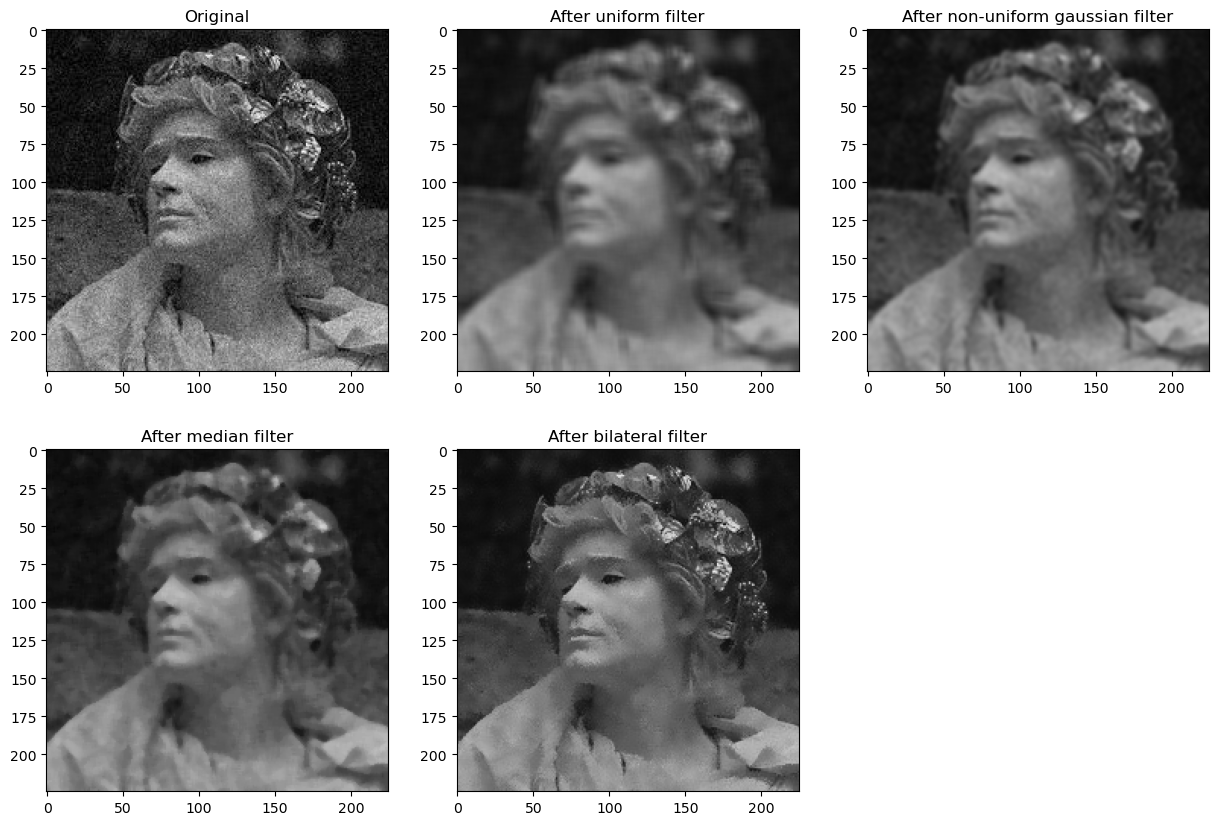

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('/Users/230363/Downloads/images.jpeg')

blur = cv2.blur(image, (7,7))

gaussian = cv2.GaussianBlur(image, (7,7), 0)

median = cv2.medianBlur(image, 5)

bilateral = cv2.bilateralFilter(image, 9, 75, 75)

plt.figure(figsize=[15,10])
plt.subplot(231);plt.imshow(image[...,::-1]);plt.title("Original")
plt.subplot(232);plt.imshow(blur[...,::-1]);plt.title("After uniform filter")
plt.subplot(233);plt.imshow(gaussian[...,::-1]);plt.title("After non-uniform gaussian filter")
plt.subplot(234);plt.imshow(median[...,::-1]);plt.title("After median filter")
plt.subplot(235);plt.imshow(bilateral[...,::-1]);plt.title("After bilateral filter")

Text(0.5, 1.0, 'Gaussian filter, sigma=15')

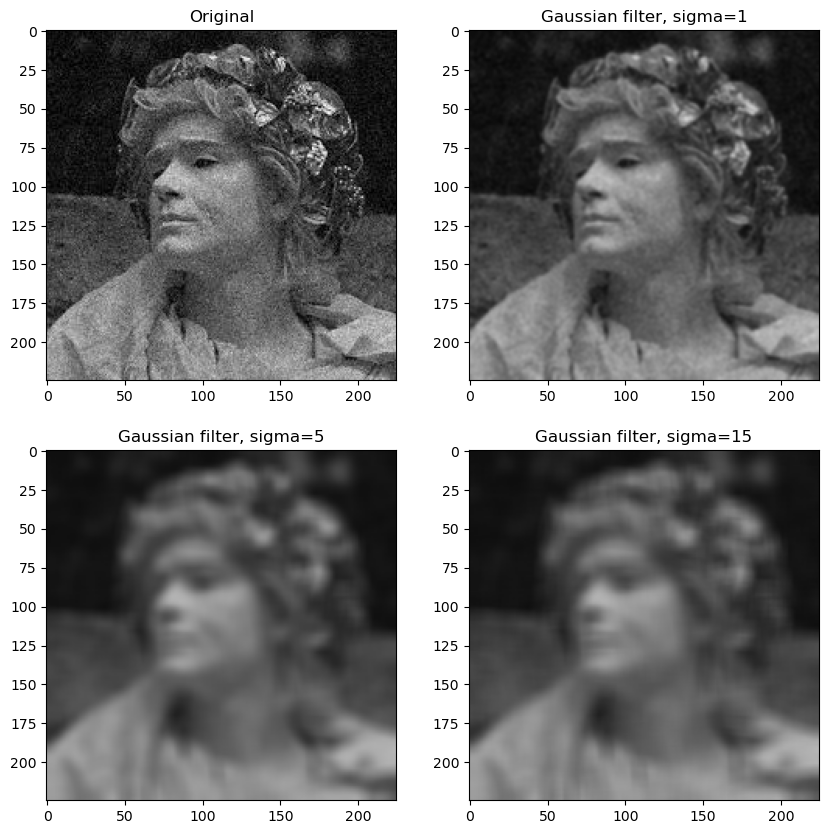

In [7]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('/Users/230363/Downloads/images.jpeg')

gaussian2 = cv2.GaussianBlur(image, (11,11), 1)
gaussian3 = cv2.GaussianBlur(image, (11,11), 5)
gaussian5 = cv2.GaussianBlur(image, (11,11), 15)

plt.figure(figsize=[10,10])
plt.subplot(221);plt.imshow(image[...,::-1]);plt.title("Original");
plt.subplot(222);plt.imshow(gaussian2[...,::-1]);plt.title("Gaussian filter, sigma=1")
plt.subplot(223);plt.imshow(gaussian3[...,::-1]);plt.title("Gaussian filter, sigma=5")
plt.subplot(224);plt.imshow(gaussian5[...,::-1]);plt.title("Gaussian filter, sigma=15")

Text(0.5, 1.0, 'result')

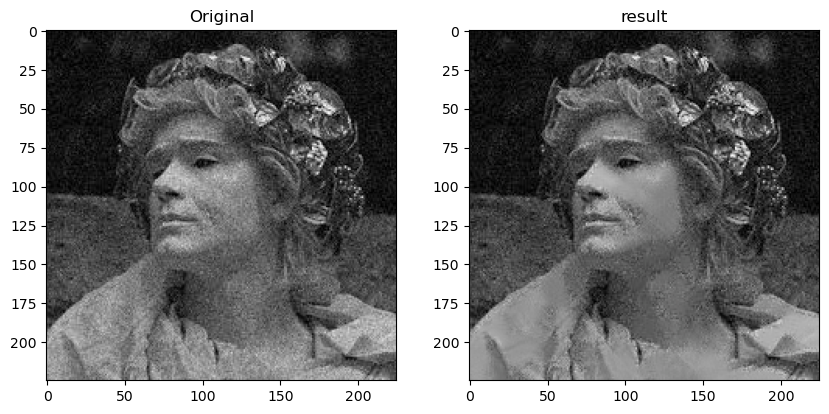

In [8]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('/Users/230363/Downloads/images.jpeg')

dst = cv2.fastNlMeansDenoisingColored(image, None, 6, 6, 7, 21)

plt.figure(figsize=[10,10])
plt.subplot(221);plt.imshow(image[...,::-1]);plt.title("Original")
plt.subplot(222);plt.imshow(dst[...,::-1]);plt.title("result")

[[-0.11111111 -0.11111111 -0.11111111]
 [-0.11111111  1.88888889 -0.11111111]
 [-0.11111111 -0.11111111 -0.11111111]]


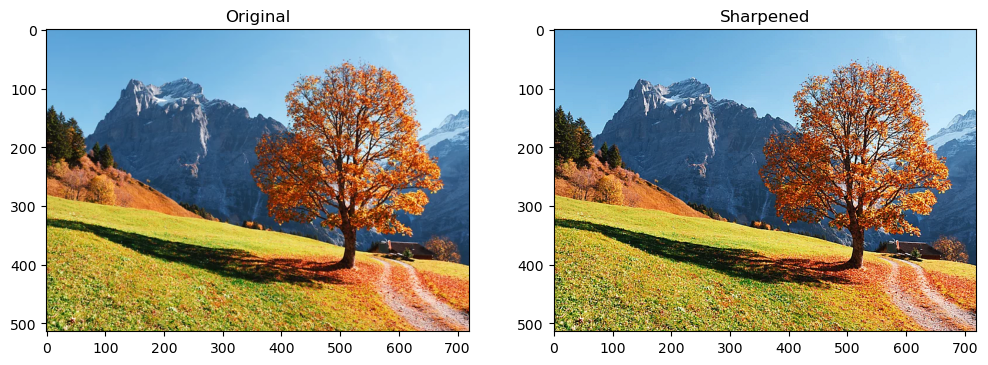

In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('/Users/230363/Downloads/img.png')

kernel1 = np.array([[0,0,0],
                              [0,2,0],
                              [0,0,0]])

kernel2 = 1/9*np.array([[1,1,1],
                              [1,1,1],
                              [1,1,1]])

final_kernel = kernel1-kernel2

sharpened = cv2.filter2D(image, -1, final_kernel)

plt.figure(figsize=[12,7])
plt.subplot(121);plt.imshow(image[...,::-1]);plt.title("Original")
plt.subplot(122);plt.imshow(sharpened[...,::-1]);plt.title("Sharpened")
print(final_kernel)

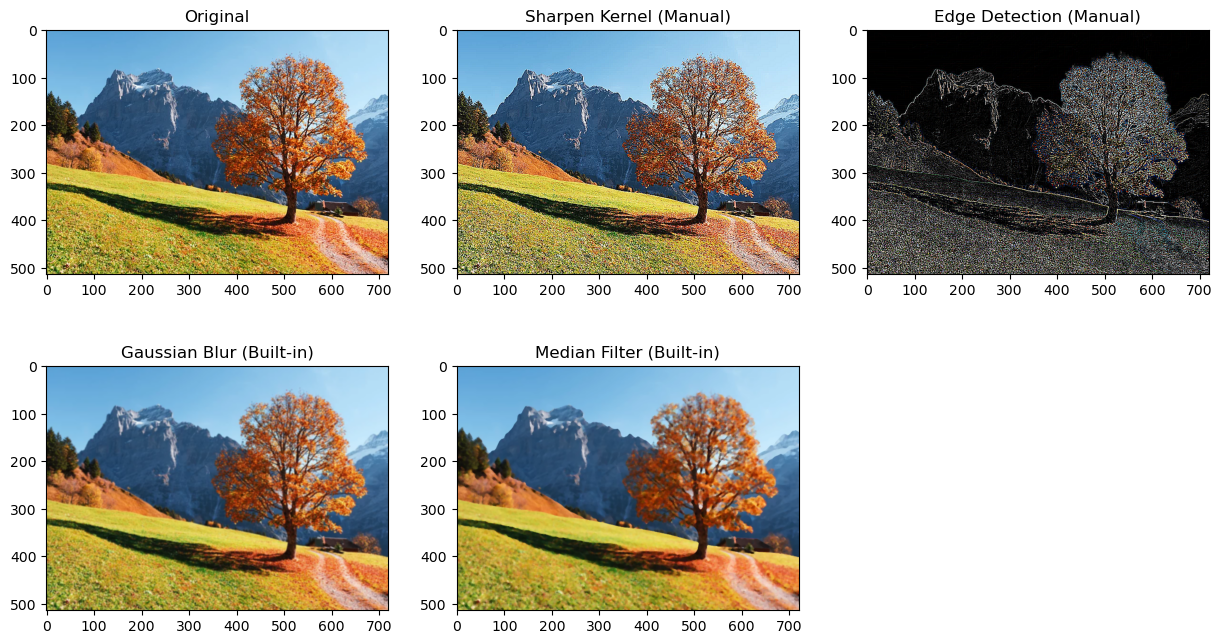

In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('/Users/230363/Downloads/img.png')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

sharpen_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

edge_kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

sharpened = cv2.filter2D(image, -1, sharpen_kernel)

edges = cv2.filter2D(image, -1, edge_kernel)

gaussian = cv2.GaussianBlur(image, (5,5), 0)

median = cv2.medianBlur(image, 5)

plt.figure(figsize=(15,8))

plt.subplot(231)
plt.imshow(image)
plt.title("Original")

plt.subplot(232)
plt.imshow(sharpened)
plt.title("Sharpen Kernel (Manual)")

plt.subplot(233)
plt.imshow(edges)
plt.title("Edge Detection (Manual)")

plt.subplot(234)
plt.imshow(gaussian)
plt.title("Gaussian Blur (Built-in)")

plt.subplot(235)
plt.imshow(median)
plt.title("Median Filter (Built-in)")

plt.show()

Text(0.5, 1.0, 'Sharpened')

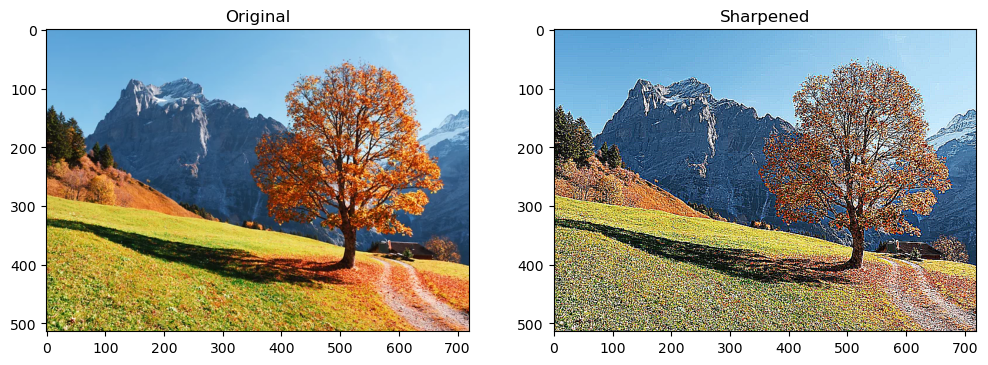

In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('/Users/230363/Downloads/img.png')

kernel_sharpening = np.array([[-1,-1,-1],
                              [-1,9,-1],
                              [-1,-1,-1]])

sharpened = cv2.filter2D(image, -1, kernel_sharpening)

plt.figure(figsize=[12,7])
plt.subplot(121);plt.imshow(image[...,::-1]);plt.title("Original")
plt.subplot(122);plt.imshow(sharpened[...,::-1]);plt.title("Sharpened")


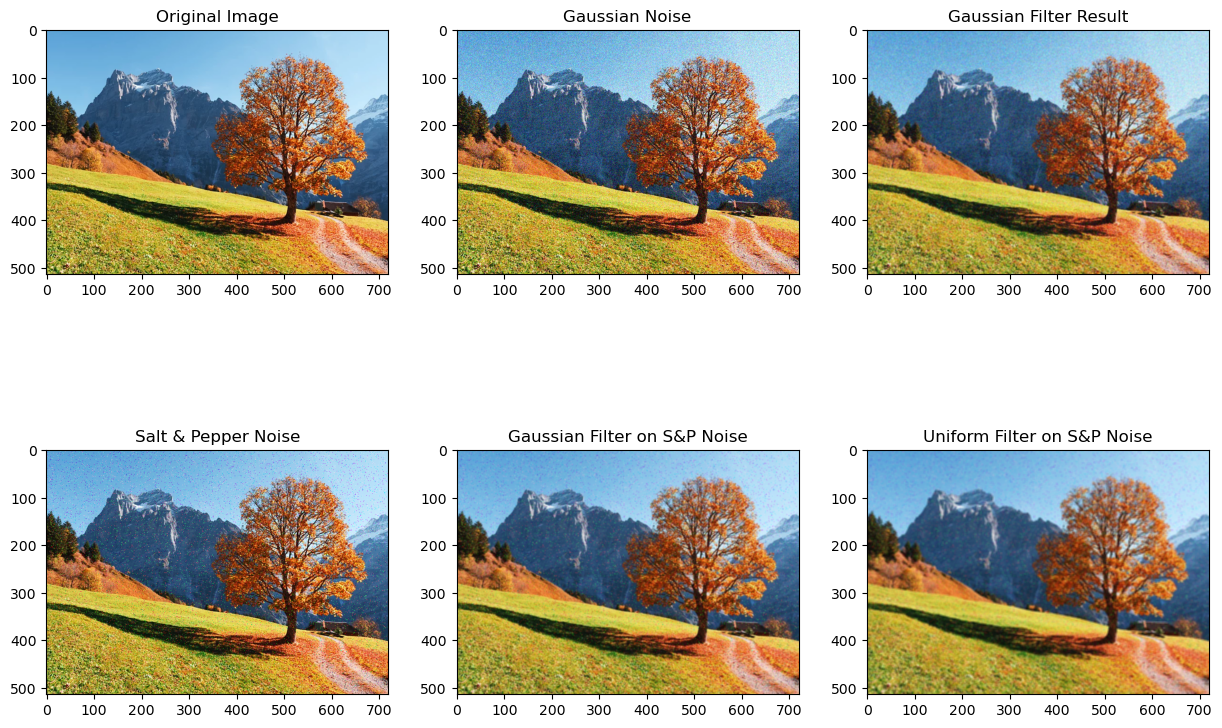

In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('/Users/230363/Downloads/img.png')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

row, col, ch = image.shape

mean = 0
sigma = 25

gaussian_noise = np.random.normal(mean, sigma, (row, col, ch))
gaussian_noise = gaussian_noise.reshape(row, col, ch)

noisy_gaussian = image + gaussian_noise
noisy_gaussian = np.clip(noisy_gaussian, 0, 255).astype(np.uint8)

noisy_sp = image.copy()

prob = 0.02

# Salt noise
num_salt = np.ceil(prob * image.size * 0.5)
coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
noisy_sp[tuple(coords)] = 255

# Pepper noise
num_pepper = np.ceil(prob * image.size * 0.5)
coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
noisy_sp[tuple(coords)] = 0

uniform_gaussian = cv2.blur(noisy_gaussian, (5,5))
uniform_sp = cv2.blur(noisy_sp, (5,5))

gaussian_filtered_gaussian = cv2.GaussianBlur(noisy_gaussian, (5,5), 0)
gaussian_filtered_sp = cv2.GaussianBlur(noisy_sp, (5,5), 0)

plt.figure(figsize=(15,10))

plt.subplot(231)
plt.imshow(image)
plt.title("Original Image")

plt.subplot(232)
plt.imshow(noisy_gaussian)
plt.title("Gaussian Noise")

plt.subplot(233)
plt.imshow(gaussian_filtered_gaussian)
plt.title("Gaussian Filter Result")

plt.subplot(234)
plt.imshow(noisy_sp)
plt.title("Salt & Pepper Noise")

plt.subplot(235)
plt.imshow(gaussian_filtered_sp)
plt.title("Gaussian Filter on S&P Noise")

plt.subplot(236)
plt.imshow(uniform_sp)
plt.title("Uniform Filter on S&P Noise")

plt.show()

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time
image = cv2.imread('/Users/230363/Downloads/img.png')
kernel = np.ones((5,5), np.float32) / 25

runs = 100

filter2d_times = []
gaussian_times = []

for i in range(runs):

    start = time.time()
    result1 = cv2.filter2D(image, -1, kernel)
    end = time.time()
    filter2d_times.append(end - start)

    start = time.time()
    result2 = cv2.GaussianBlur(image, (5,5), 0)
    end = time.time()
    gaussian_times.append(end - start)
    runs = 100

avg_filter2d = np.mean(filter2d_times)
avg_gaussian = np.mean(gaussian_times)

print("Average execution time (filter2D):", avg_filter2d)
print("Average execution time (GaussianBlur):", avg_gaussian)

Average execution time (filter2D): 0.002337789535522461
Average execution time (GaussianBlur): 0.00019579172134399415


In [20]:
import numpy as np
def check_matrix_range(matrix):
    
    mat = np.array(matrix)

    min_val = np.min(mat)
    max_val = np.max(mat)

    dtype = mat.dtype

    print(f"Matrix type: {dtype}")
    print(f"Minimum value: {min_val}")
    print(f"Maximum value: {max_val}")
    print(f"Range: {min_val} to {max_val}")

matrix = [[1, 2, 3],
          [4, 5, 6],
          [7, 8, 9]]

check_matrix_range(matrix)

Matrix type: int64
Minimum value: 1
Maximum value: 9
Range: 1 to 9


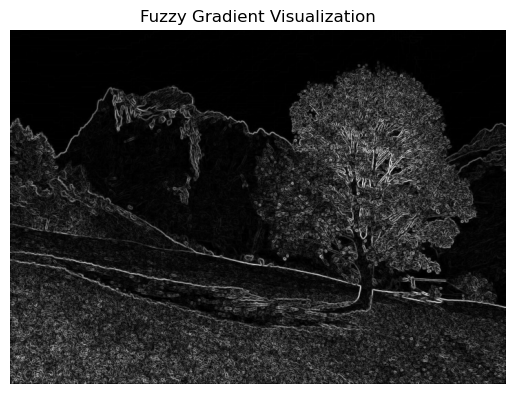

In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('/Users/230363/Downloads/img.png', cv2.IMREAD_GRAYSCALE)

Gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
Gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
grad_mag = np.sqrt(Gx**2 + Gy**2)

Gmin, Gmax = grad_mag.min(), grad_mag.max()
fuzzy_grad = (grad_mag - Gmin) / (Gmax - Gmin)

plt.imshow(fuzzy_grad, cmap='gray')
plt.title('Fuzzy Gradient Visualization')
plt.axis('off')
plt.show()     

Min: 0
Max: 255
Min: 0
Max: 124


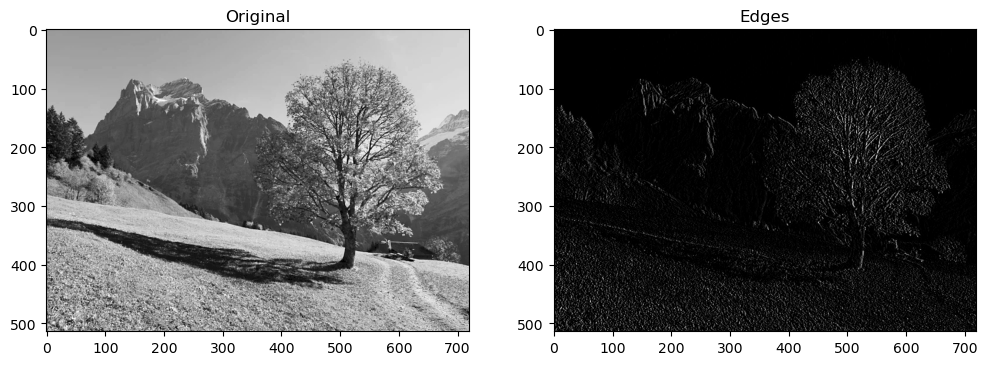

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def print_min_and_max(img):
    print("Min:", np.min(img))
    print("Max:", np.max(img))
    
image = cv2.imread('/Users/230363/Downloads/img.png',0)

kernel = np.array([[0,0,0],
                   [-1/2,0,1/2],
                   [0,0,0]])

edges = cv2.filter2D(image, -1 , kernel)

plt.figure(figsize=[12,7])
plt.subplot(121);plt.imshow(image, cmap='gray');plt.title("Original");
plt.subplot(122);plt.imshow(edges, cmap='gray');plt.title("Edges");

print_min_and_max(image)
print_min_and_max(edges)

Kernel Sum: 9


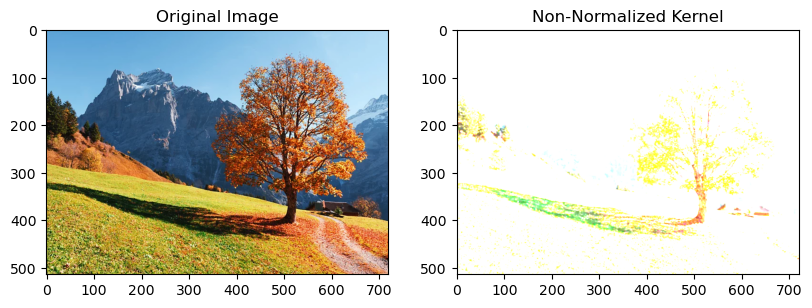

In [30]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
image = cv2.imread('/Users/230363/Downloads/img.png')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

kernel_not_normalized = np.array([
    [1,1,1],
    [1,1,1],
    [1,1,1]
])

print("Kernel Sum:", np.sum(kernel_not_normalized))

bright_image = cv2.filter2D(image, -1, kernel_not_normalized)

plt.figure(figsize=(15,6))

plt.subplot(131)
plt.imshow(image)
plt.title("Original Image")

plt.subplot(132)
plt.imshow(bright_image)
plt.title("Non-Normalized Kernel")
plt.show()

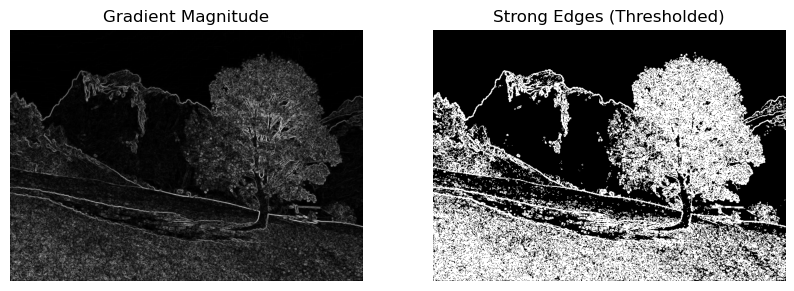

In [26]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('/Users/230363/Downloads/img.png', cv2.IMREAD_GRAYSCALE)

Gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
Gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
grad_mag = np.sqrt(Gx**2 + Gy**2)

T = 100  
edges = np.uint8((grad_mag > T) * 255)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(grad_mag, cmap='gray')
plt.title('Gradient Magnitude')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(edges, cmap='gray')
plt.title('Strong Edges (Thresholded)')
plt.axis('off')
plt.show()

Min: 0
Max: 255
Min: 0
Max: 124


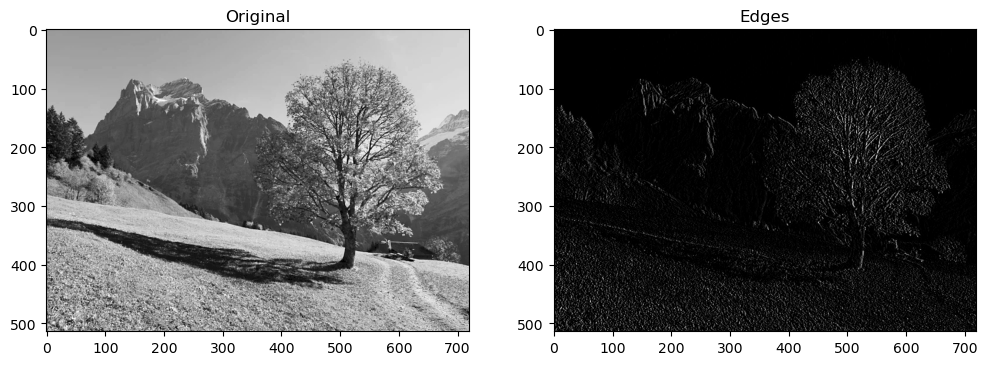

In [27]:

import cv2
import numpy as np
import matplotlib.pyplot as plt


image = cv2.imread('/Users/230363/Downloads/img.png',0)

kernel = np.array([[0,0,0],
                   [-1/2,0,1/2],
                   [0,0,0]])

edges = cv2.filter2D(image, -1 , kernel)

plt.figure(figsize=[12,7])
plt.subplot(121);plt.imshow(image, cmap='gray');plt.title("Original");
plt.subplot(122);plt.imshow(edges, cmap='gray');plt.title("Edges");

print_min_and_max(image)
print_min_and_max(edges)
     

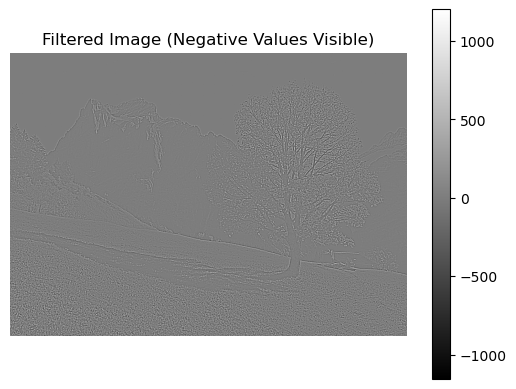

In [28]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('/Users/230363/Downloads/img.png', cv2.IMREAD_GRAYSCALE)

kernel = np.array([[-1, -1, -1],
                   [-1,  8, -1],
                   [-1, -1, -1]])

filtered = cv2.filter2D(img, ddepth=cv2.CV_32F, kernel=kernel)

plt.imshow(filtered, cmap='gray')
plt.title('Filtered Image (Negative Values Visible)')
plt.colorbar()
plt.axis('off')
plt.show()

Min: 0
Max: 255
Min: -125.5
Max: 123.5


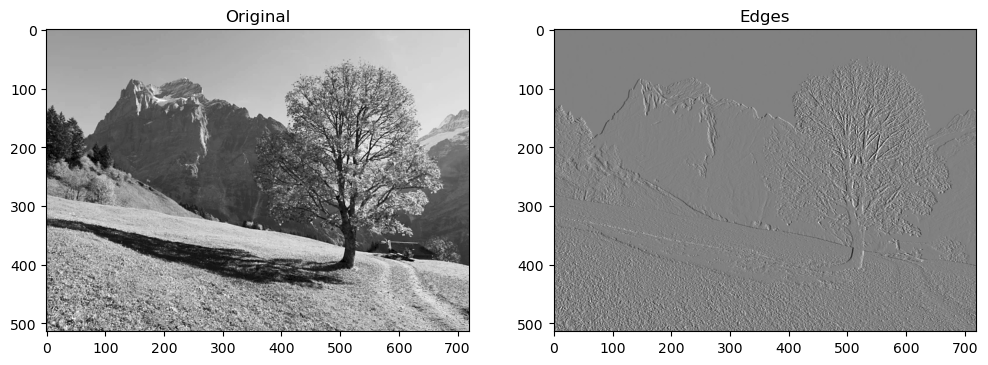

In [29]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


image = cv2.imread('/Users/230363/Downloads/img.png',0)

kernel = np.array([[0,0,0],
                   [-1/2,0,1/2],
                   [0,0,0]])

edges = cv2.filter2D(image, cv2.CV_64F , kernel)

plt.figure(figsize=[12,7])
plt.subplot(121);plt.imshow(image, cmap='gray');plt.title("Original");
plt.subplot(122);plt.imshow(edges, cmap='gray');plt.title("Edges");

print_min_and_max(image)
print_min_and_max(edges)